# Approach 1: Multiclass YOLO11 Object Detection

Train multiclass YOLO11 and YOLO26 models (3 sizes each: s/m/l) to detect and classify all 10 roadside rubbish types simultaneously.

## 1. Setup & Install

In [1]:
%pip install pandas ultralytics iterative-stratification scikit-learn matplotlib seaborn tqdm Pillow albumentations

Note: you may need to restart the kernel to use updated packages.


In [2]:
import os, shutil, random, zipfile, json, warnings
from pathlib import Path
from collections import Counter, defaultdict

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
from PIL import Image
from tqdm.auto import tqdm

warnings.filterwarnings("ignore")
random.seed(42)
np.random.seed(42)

# Class names for the 10 rubbish types
CLASS_NAMES = [
    "rubbish", "bottle", "carton", "mattress", "chair",
    "couch", "furniture", "clothes", "electrical_goods", "rug"
]
NUM_CLASSES = len(CLASS_NAMES)

# Color palette for visualization (one per class)
COLORS = plt.cm.tab10(np.linspace(0, 1, NUM_CLASSES))

## 2. Unzip Data

In [3]:
# Unzip rubbish.zip and not_rubbish.zip if the folders don't already exist
for name in ["rubbish", "not_rubbish"]:
    zip_path = Path(f"{name}.zip")
    folder_path = Path(name)
    if not folder_path.exists() and zip_path.exists():
        with zipfile.ZipFile(zip_path, "r") as zf:
            zf.extractall(".")

# Count images in each folder
rubbish_dir = Path("rubbish")
not_rubbish_dir = Path("not_rubbish")

rubbish_images = sorted(
    [p for p in rubbish_dir.iterdir() if p.suffix.lower() in (".jpg", ".jpeg", ".png")]
) if rubbish_dir.exists() else []

not_rubbish_images = sorted(
    [p for p in not_rubbish_dir.iterdir() if p.suffix.lower() in (".jpg", ".jpeg", ".png")]
) if not_rubbish_dir.exists() else []

f"Rubbish images: {len(rubbish_images)}, Not-rubbish images: {len(not_rubbish_images)}"

'Rubbish images: 666, Not-rubbish images: 6554'

## 3. Explore Dataset

### 3.1 Load all labels and count class distribution

In [4]:
label_dir = rubbish_dir  # Labels are in the rubbish folder alongside images
label_files = sorted(label_dir.glob("*.txt"))

# Parse all label files
all_annotations = {}  # stem -> list of (class_id, cx, cy, w, h)
class_counts = Counter()
empty_count = 0
non_empty_count = 0

for lf in tqdm(label_files, desc="Loading labels"):
    annotations = []
    text = lf.read_text().strip()
    if text:
        for line in text.split("\n"):
            parts = line.strip().split()
            if len(parts) == 5:
                cls_id = int(parts[0])
                coords = [float(x) for x in parts[1:]]
                annotations.append((cls_id, *coords))
                class_counts[cls_id] += 1
    all_annotations[lf.stem] = annotations
    if annotations:
        non_empty_count += 1
    else:
        empty_count += 1

total_annots = sum(class_counts.values())
f"Total label files: {len(label_files)}, Non-empty: {non_empty_count}, Empty: {empty_count}, Total annotations: {total_annots}"

Loading labels:   0%|          | 0/667 [00:00<?, ?it/s]

'Total label files: 667, Non-empty: 666, Empty: 1, Total annotations: 1299'

### 3.2 Class distribution bar chart

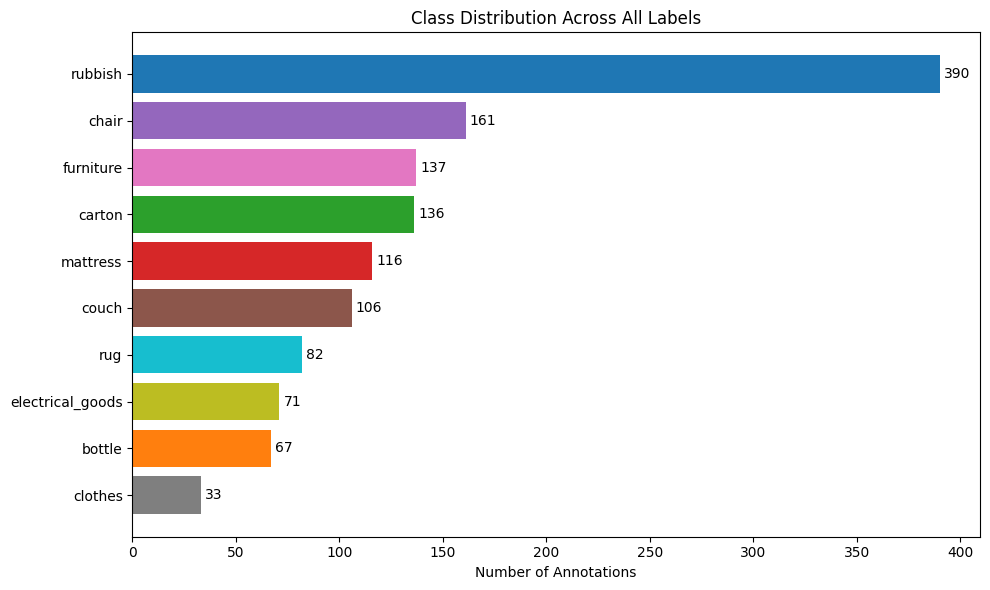

In [5]:
# Sorted horizontal bar chart of class distribution
sorted_classes = sorted(range(NUM_CLASSES), key=lambda i: class_counts.get(i, 0))

fig, ax = plt.subplots(figsize=(10, 6))
counts = [class_counts.get(i, 0) for i in sorted_classes]
names = [CLASS_NAMES[i] for i in sorted_classes]
bars = ax.barh(names, counts, color=[COLORS[i] for i in sorted_classes])
ax.bar_label(bars, padding=3)
ax.set_xlabel("Number of Annotations")
ax.set_title("Class Distribution Across All Labels")
plt.tight_layout()
plt.show()

### 3.3 Sample images with bounding boxes

In [6]:
def find_image_for_stem(stem, search_dirs):
    """Find an image file matching a given stem across search directories."""
    for d in search_dirs:
        for ext in (".jpg", ".jpeg", ".png"):
            p = d / (stem + ext)
            if p.exists():
                return p
    return None


def draw_bboxes(ax, img, annotations, class_names, colors):
    """Draw bounding boxes on an axes given YOLO-format annotations."""
    ax.imshow(img)
    h, w = img.shape[:2] if hasattr(img, "shape") else (img.size[1], img.size[0])
    if isinstance(img, Image.Image):
        w, h = img.size
    for cls_id, cx, cy, bw, bh in annotations:
        x1 = (cx - bw / 2) * w
        y1 = (cy - bh / 2) * h
        rect_w = bw * w
        rect_h = bh * h
        color = colors[cls_id]
        rect = plt.Rectangle((x1, y1), rect_w, rect_h,
                             linewidth=2, edgecolor=color, facecolor="none")
        ax.add_patch(rect)
        ax.text(x1, y1 - 4, class_names[cls_id], color=color,
                fontsize=7, fontweight="bold",
                bbox=dict(facecolor="black", alpha=0.5, pad=1, edgecolor="none"))
    ax.axis("off")

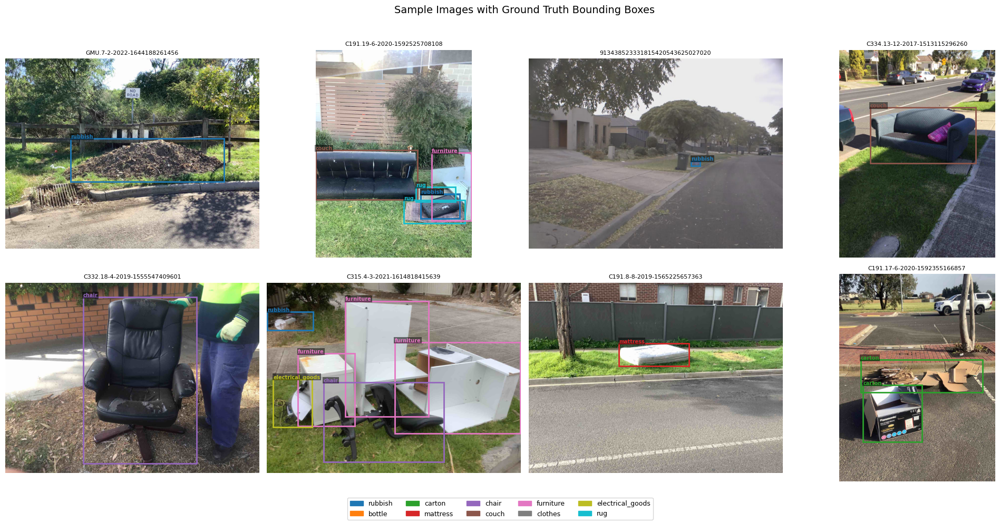

In [7]:
# Pick 8 sample images that have annotations
search_dirs = [rubbish_dir]
if not_rubbish_dir.exists():
    search_dirs.append(not_rubbish_dir)

annotated_stems = [s for s, a in all_annotations.items() if a]
sample_stems = random.sample(annotated_stems, min(8, len(annotated_stems)))

fig, axes = plt.subplots(2, 4, figsize=(20, 10))
for ax, stem in zip(axes.flat, sample_stems):
    img_path = find_image_for_stem(stem, search_dirs)
    if img_path:
        img = Image.open(img_path).convert("RGB")
        draw_bboxes(ax, img, all_annotations[stem], CLASS_NAMES, COLORS)
        ax.set_title(stem[:30], fontsize=8)
    else:
        ax.set_visible(False)

# Legend
handles = [mpatches.Patch(color=COLORS[i], label=CLASS_NAMES[i]) for i in range(NUM_CLASSES)]
fig.legend(handles=handles, loc="lower center", ncol=5, fontsize=9)
fig.suptitle("Sample Images with Ground Truth Bounding Boxes", fontsize=14)
plt.tight_layout(rect=[0, 0.06, 1, 0.96])
plt.show()

### 3.4 Summary statistics

In [8]:
summary = pd.DataFrame({
    "Class": CLASS_NAMES,
    "ID": list(range(NUM_CLASSES)),
    "Annotations": [class_counts.get(i, 0) for i in range(NUM_CLASSES)]
})
summary["Percentage"] = (summary["Annotations"] / summary["Annotations"].sum() * 100).round(1)
summary = summary.sort_values("Annotations", ascending=False).reset_index(drop=True)
summary

,Class,ID,Annotations,Percentage
0,rubbish,0,390,30.0
1,chair,4,161,12.4
2,furniture,6,137,10.5
3,carton,2,136,10.5
4,mattress,3,116,8.9
5,couch,5,106,8.2
6,rug,9,82,6.3
7,electrical_goods,8,71,5.5
8,bottle,1,67,5.2
9,clothes,7,33,2.5


## 4. Prepare YOLO Dataset

### 4.1 Match images to labels

In [9]:
# Build mapping: stem -> image path (for rubbish images)
rubbish_stem_to_path = {}
for p in rubbish_images:
    rubbish_stem_to_path[p.stem] = p

# Find rubbish images that have matching label files (non-empty or empty)
matched_rubbish = []  # (stem, image_path, annotations)
skipped_no_image = 0

for stem, annots in tqdm(all_annotations.items(), desc="Matching labels to images"):
    if stem in rubbish_stem_to_path:
        matched_rubbish.append((stem, rubbish_stem_to_path[stem], annots))
    else:
        # Check if image exists in rubbish dir with different extension
        img_path = find_image_for_stem(stem, [rubbish_dir])
        if img_path:
            matched_rubbish.append((stem, img_path, annots))
        else:
            skipped_no_image += 1

f"Matched rubbish images: {len(matched_rubbish)}, Skipped (no image): {skipped_no_image}"

Matching labels to images:   0%|          | 0/667 [00:00<?, ?it/s]

'Matched rubbish images: 666, Skipped (no image): 1'

### 4.2 Sample not_rubbish images to reach 1,200 total

In [10]:
# Determine how many not_rubbish images to sample
target_total = 1200
n_rubbish = len(matched_rubbish)
n_not_rubbish_needed = max(0, target_total - n_rubbish)

# Sample from not_rubbish images
if not_rubbish_images and n_not_rubbish_needed > 0:
    sampled_not_rubbish = random.sample(
        not_rubbish_images, min(n_not_rubbish_needed, len(not_rubbish_images))
    )
else:
    sampled_not_rubbish = []

# Build the full dataset list: (stem, image_path, annotations)
dataset = list(matched_rubbish)
for p in sampled_not_rubbish:
    dataset.append((p.stem, p, []))  # empty annotations for not_rubbish

f"Total dataset: {len(dataset)} (rubbish: {n_rubbish}, not_rubbish sampled: {len(sampled_not_rubbish)})"

'Total dataset: 1200 (rubbish: 666, not_rubbish sampled: 534)'

### 4.3 Stratified train/val/test split

In [11]:
from iterstrat.ml_stratifiers import MultilabelStratifiedShuffleSplit

# Build multi-label binary matrix (N x NUM_CLASSES+1)
# Extra column for "background" (no annotations) to stratify empty images too
n = len(dataset)
labels_matrix = np.zeros((n, NUM_CLASSES + 1), dtype=int)
for i, (stem, img_path, annots) in enumerate(dataset):
    if not annots:
        labels_matrix[i, NUM_CLASSES] = 1  # background class
    else:
        for cls_id, *_ in annots:
            labels_matrix[i, cls_id] = 1

indices = np.arange(n)

# First split: separate test set (20%)
splitter1 = MultilabelStratifiedShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
train_val_idx, test_idx = next(splitter1.split(indices, labels_matrix))

# Second split: separate val set (10% of total ≈ 12.5% of remaining 80%)
val_frac = 0.1 / 0.8
splitter2 = MultilabelStratifiedShuffleSplit(n_splits=1, test_size=val_frac, random_state=42)
train_idx, val_idx = next(splitter2.split(train_val_idx, labels_matrix[train_val_idx]))
# Map back to original indices
train_idx = train_val_idx[train_idx]
val_idx = train_val_idx[val_idx]

f"Train: {len(train_idx)}, Val: {len(val_idx)}, Test: {len(test_idx)}"

'Train: 843, Val: 117, Test: 240'

### 4.4 Copy images and labels into YOLO directory structure

In [12]:
dataset_dir = Path("dataset")

# Remove any previous dataset directory to avoid stale data
if dataset_dir.exists():
    shutil.rmtree(dataset_dir)

for split in ["train", "val", "test"]:
    (dataset_dir / split / "images").mkdir(parents=True)
    (dataset_dir / split / "labels").mkdir(parents=True)

def copy_sample(idx, split):
    """Copy an image and its label file to the appropriate split directory."""
    stem, img_path, annots = dataset[idx]
    # Copy image (preserve original extension)
    dst_img = dataset_dir / split / "images" / img_path.name
    if not dst_img.exists():
        shutil.copy2(img_path, dst_img)
    # Write label file
    dst_label = dataset_dir / split / "labels" / (img_path.stem + ".txt")
    lines = []
    for cls_id, cx, cy, w, h in annots:
        lines.append(f"{cls_id} {cx:.6f} {cy:.6f} {w:.6f} {h:.6f}")
    dst_label.write_text("\n".join(lines))

for idx in tqdm(train_idx, desc="Copying train"):
    copy_sample(idx, "train")
for idx in tqdm(val_idx, desc="Copying val"):
    copy_sample(idx, "val")
for idx in tqdm(test_idx, desc="Copying test"):
    copy_sample(idx, "test")

# Verify counts
for split in ["train", "val", "test"]:
    n_imgs = len(list((dataset_dir / split / "images").iterdir()))
    n_lbls = len(list((dataset_dir / split / "labels").iterdir()))
    f"{split}: {n_imgs} images, {n_lbls} labels"

Copying train:   0%|          | 0/843 [00:00<?, ?it/s]

Copying val:   0%|          | 0/117 [00:00<?, ?it/s]

Copying test:   0%|          | 0/240 [00:00<?, ?it/s]

In [13]:
# Verify counts
for split in ["train", "val", "test"]:
    n_imgs = len(list((dataset_dir / split / "images").iterdir()))
    n_lbls = len(list((dataset_dir / split / "labels").iterdir()))
    display(f"{split}: {n_imgs} images, {n_lbls} labels")

'train: 843 images, 843 labels'

'val: 117 images, 117 labels'

'test: 240 images, 240 labels'

### 4.5 Create data.yaml

In [14]:
import yaml

data_yaml = {
    "path": str(dataset_dir.resolve()),
    "train": "train/images",
    "val": "val/images",
    "test": "test/images",
    "nc": NUM_CLASSES,
    "names": CLASS_NAMES
}

yaml_path = dataset_dir / "data.yaml"
with open(yaml_path, "w") as f:
    yaml.dump(data_yaml, f, default_flow_style=False, sort_keys=False)

yaml_path.read_text()

'path: /dataset\ntrain: train/images\nval: val/images\ntest: test/images\nnc: 10\nnames:\n- rubbish\n- bottle\n- carton\n- mattress\n- chair\n- couch\n- furniture\n- clothes\n- electrical_goods\n- rug\n'

### 4.6 Visualize split class distribution

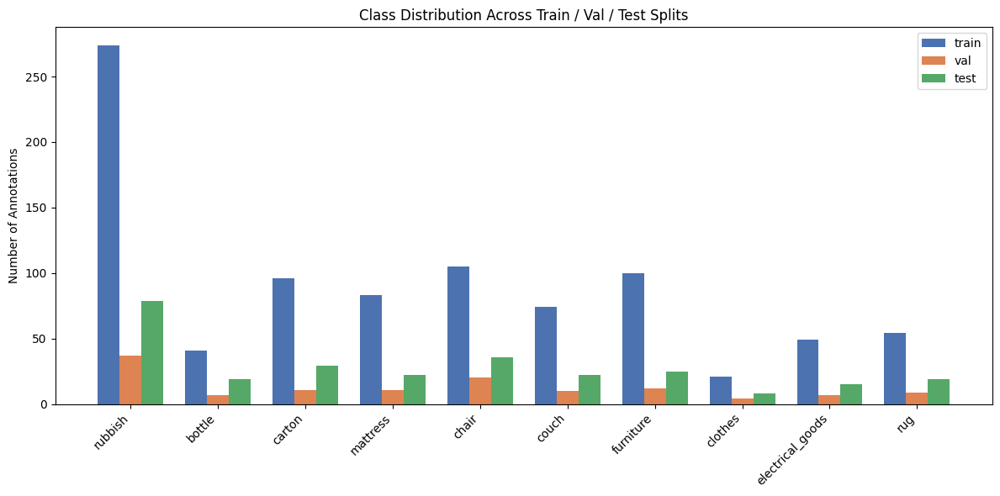

In [15]:
# Count class annotations per split
split_counts = {"train": Counter(), "val": Counter(), "test": Counter()}
for split, idxs in [("train", train_idx), ("val", val_idx), ("test", test_idx)]:
    for idx in idxs:
        _, _, annots = dataset[idx]
        for cls_id, *_ in annots:
            split_counts[split][cls_id] += 1

fig, ax = plt.subplots(figsize=(12, 6))
x = np.arange(NUM_CLASSES)
width = 0.25
for i, (split, color) in enumerate([("train", "#4C72B0"), ("val", "#DD8452"), ("test", "#55A868")]):
    counts = [split_counts[split].get(c, 0) for c in range(NUM_CLASSES)]
    ax.bar(x + i * width, counts, width, label=split, color=color)

ax.set_xticks(x + width)
ax.set_xticklabels(CLASS_NAMES, rotation=45, ha="right")
ax.set_ylabel("Number of Annotations")
ax.set_title("Class Distribution Across Train / Val / Test Splits")
ax.legend()
plt.tight_layout()
plt.show()

## 5. Copy-Paste Augmentation for Minority Classes

### 5.1 Build crop library from minority classes

In [16]:
MINORITY_CLASSES = [1, 7, 8, 9]  # bottle, clothes, electrical_goods, rug
MINORITY_NAMES = [CLASS_NAMES[i] for i in MINORITY_CLASSES]
PADDING = 0.15  # 15% padding around crops

# Collect crops from training images only
crop_library = defaultdict(list)  # class_id -> list of (PIL crop image, original_annot)

for idx in tqdm(train_idx, desc="Building crop library"):
    stem, img_path, annots = dataset[idx]
    if not annots:
        continue
    minority_annots = [(cls_id, cx, cy, w, h) for cls_id, cx, cy, w, h in annots if cls_id in MINORITY_CLASSES]
    if not minority_annots:
        continue

    img = Image.open(img_path).convert("RGB")
    iw, ih = img.size

    for cls_id, cx, cy, bw, bh in minority_annots:
        # Convert normalized coords to pixel coords with padding
        pad_w = bw * PADDING
        pad_h = bh * PADDING
        x1 = max(0, int((cx - bw / 2 - pad_w) * iw))
        y1 = max(0, int((cy - bh / 2 - pad_h) * ih))
        x2 = min(iw, int((cx + bw / 2 + pad_w) * iw))
        y2 = min(ih, int((cy + bh / 2 + pad_h) * ih))
        if x2 > x1 and y2 > y1:
            crop = img.crop((x1, y1, x2, y2))
            crop_library[cls_id].append(crop)

{cls: len(crops) for cls, crops in crop_library.items()}

Building crop library:   0%|          | 0/843 [00:00<?, ?it/s]

{9: 54, 1: 41, 8: 49, 7: 21}

### 5.2 Generate augmented training images with pasted crops

In [17]:
def iou(box_a, box_b):
    """
    Compute IoU between two YOLO-format boxes (cx, cy, w, h), all normalized.

    Args:
        box_a: Tuple (cx, cy, w, h).
        box_b: Tuple (cx, cy, w, h).

    Returns:
        IoU as a float in [0, 1].
    """
    ax1, ay1 = box_a[0] - box_a[2] / 2, box_a[1] - box_a[3] / 2
    ax2, ay2 = box_a[0] + box_a[2] / 2, box_a[1] + box_a[3] / 2
    bx1, by1 = box_b[0] - box_b[2] / 2, box_b[1] - box_b[3] / 2
    bx2, by2 = box_b[0] + box_b[2] / 2, box_b[1] + box_b[3] / 2

    inter_w = max(0, min(ax2, bx2) - max(ax1, bx1))
    inter_h = max(0, min(ay2, by2) - max(ay1, by1))
    inter = inter_w * inter_h

    union = box_a[2] * box_a[3] + box_b[2] * box_b[3] - inter
    return inter / union if union > 0 else 0.0


def paste_crop_on_image(base_img, crop_img, cls_id, existing_annots, max_attempts=10):
    """
    Paste a crop onto the base image at a position that does not overlap existing boxes.

    Args:
        base_img: PIL Image to paste onto.
        crop_img: PIL Image crop to paste.
        cls_id: Class ID of the crop.
        existing_annots: List of existing (cls_id, cx, cy, w, h) normalized annotations.
        max_attempts: Number of random positions to try before giving up.

    Returns:
        Tuple of (modified PIL Image, annotation (cls_id, cx, cy, w, h) normalized),
        or (base_img, None) if no non-overlapping position was found.
    """
    bw, bh = base_img.size
    cw, ch = crop_img.size

    scale = random.uniform(0.15, 0.40)
    new_w = int(bw * scale)
    new_h = int(new_w * ch / cw)
    if new_h > bh * 0.6:
        new_h = int(bh * 0.4)
        new_w = int(new_h * cw / ch)

    resized_crop = crop_img.resize((max(new_w, 1), max(new_h, 1)), Image.LANCZOS)

    max_x = max(bw - new_w, 1)
    max_y = max(bh - new_h, 1)

    for _ in range(max_attempts):
        px = random.randint(0, max_x)
        py = random.randint(0, max_y)

        candidate_cx = (px + new_w / 2) / bw
        candidate_cy = (py + new_h / 2) / bh
        candidate_w = new_w / bw
        candidate_h = new_h / bh
        candidate_box = (candidate_cx, candidate_cy, candidate_w, candidate_h)

        overlaps = any(
            iou(candidate_box, (cx, cy, w, h)) > 0
            for _, cx, cy, w, h in existing_annots
        )
        if not overlaps:
            result = base_img.copy()
            result.paste(resized_crop, (px, py))
            return result, (cls_id, candidate_cx, candidate_cy, candidate_w, candidate_h)

    return base_img, None


In [18]:
# Generate ~250 augmented images from training data
N_AUG = 250
aug_images_dir = dataset_dir / "train" / "images"
aug_labels_dir = dataset_dir / "train" / "labels"

train_img_paths = sorted(aug_images_dir.glob("*"))
train_img_paths = [p for p in train_img_paths if p.suffix.lower() in (".jpg", ".jpeg", ".png")]

augmented_samples = []  # track for visualization
n_generated = 0

for i in tqdm(range(N_AUG), desc="Generating augmented images"):
    base_path = random.choice(train_img_paths)
    base_img = Image.open(base_path).convert("RGB")

    label_path = aug_labels_dir / (base_path.stem + ".txt")
    existing_annots = []
    if label_path.exists():
        text = label_path.read_text().strip()
        if text:
            for line in text.split("\n"):
                parts = line.strip().split()
                if len(parts) == 5:
                    existing_annots.append(
                        (int(parts[0]), float(parts[1]), float(parts[2]), float(parts[3]), float(parts[4]))
                    )

    available = [c for c in MINORITY_CLASSES if crop_library[c]]
    if not available:
        continue
    cls_id = random.choice(available)
    crop_img = random.choice(crop_library[cls_id])

    aug_img, new_annot = paste_crop_on_image(base_img, crop_img, cls_id, existing_annots)
    if new_annot is None:
        continue

    aug_name = f"aug_{i:04d}_{base_path.stem}{base_path.suffix}"
    aug_img_path = aug_images_dir / aug_name
    aug_img.save(aug_img_path)

    all_annots = existing_annots + [new_annot]
    aug_label_path = aug_labels_dir / (aug_img_path.stem + ".txt")
    lines = [f"{cls_id} {cx:.6f} {cy:.6f} {w:.6f} {h:.6f}" for cls_id, cx, cy, w, h in all_annots]
    aug_label_path.write_text("\n".join(lines))

    n_generated += 1
    if len(augmented_samples) < 3:
        augmented_samples.append((aug_img_path, all_annots, base_path))

f"Generated {n_generated} augmented images (skipped {N_AUG - n_generated} with no valid placement)"


Generating augmented images:   0%|          | 0/250 [00:00<?, ?it/s]

'Generated 237 augmented images (skipped 13 with no valid placement)'

### 5.3 Before/after examples of augmented images

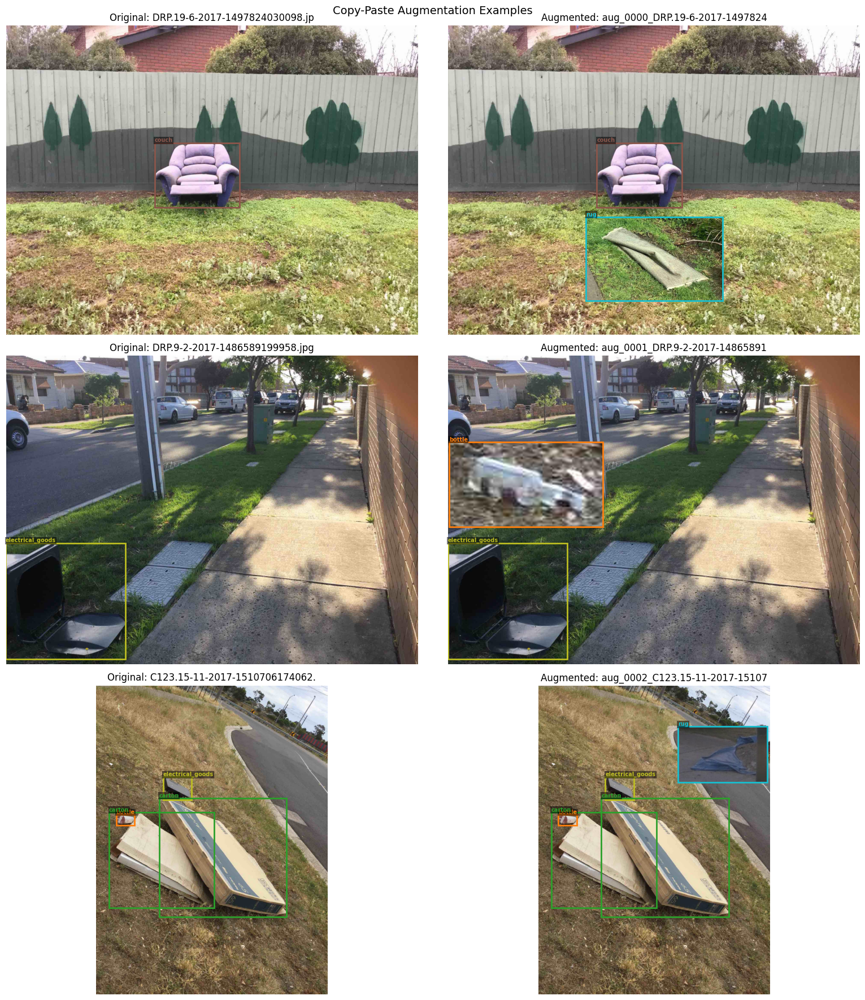

In [19]:
fig, axes = plt.subplots(3, 2, figsize=(16, 18))
for row, (aug_path, aug_annots, orig_path) in enumerate(augmented_samples[:3]):
    orig_img = Image.open(orig_path).convert("RGB")
    orig_label = aug_labels_dir / (orig_path.stem + ".txt")
    orig_annots = []
    if orig_label.exists():
        text = orig_label.read_text().strip()
        if text:
            for line in text.split("\n"):
                parts = line.strip().split()
                if len(parts) == 5:
                    orig_annots.append(
                        (int(parts[0]), float(parts[1]), float(parts[2]), float(parts[3]), float(parts[4]))
                    )
    draw_bboxes(axes[row, 0], orig_img, orig_annots, CLASS_NAMES, COLORS)
    axes[row, 0].set_title(f"Original: {orig_path.name[:30]}")

    aug_img = Image.open(aug_path).convert("RGB")
    draw_bboxes(axes[row, 1], aug_img, aug_annots, CLASS_NAMES, COLORS)
    axes[row, 1].set_title(f"Augmented: {aug_path.name[:30]}")

plt.suptitle("Copy-Paste Augmentation Examples", fontsize=14)
plt.tight_layout()
plt.show()

### 5.4 Updated class distribution after augmentation

Counting updated labels:   0%|          | 0/1080 [00:00<?, ?it/s]

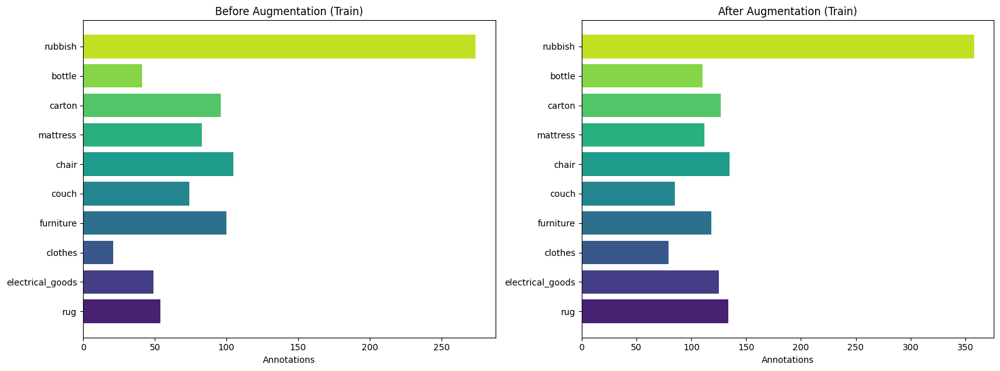

In [20]:
# Recount all training annotations after augmentation
updated_counts = Counter()
train_label_files = list((dataset_dir / "train" / "labels").glob("*.txt"))

for lf in tqdm(train_label_files, desc="Counting updated labels"):
    text = lf.read_text().strip()
    if text:
        for line in text.split("\n"):
            parts = line.strip().split()
            if len(parts) >= 1:
                updated_counts[int(parts[0])] += 1

before_counts = Counter()
for idx in train_idx:
    _, _, annots = dataset[idx]
    for cls_id, *_ in annots:
        before_counts[cls_id] += 1

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
for ax, counts, title in [
    (axes[0], before_counts, "Before Augmentation (Train)"),
    (axes[1], updated_counts, "After Augmentation (Train)"),
]:
    names = [CLASS_NAMES[c] for c in range(NUM_CLASSES)]
    vals = [counts.get(c, 0) for c in range(NUM_CLASSES)]
    ax.barh(names[::-1], vals[::-1], color=sns.color_palette("viridis", NUM_CLASSES))
    ax.set_xlabel("Annotations")
    ax.set_title(title)

plt.tight_layout()
plt.show()

## 6. Train YOLO11 Models (3 sizes)

In [21]:
from ultralytics import YOLO

# Common training hyperparameters
COMMON_ARGS = dict(
    data=str(yaml_path.resolve()),
    imgsz=960,
    epochs=200,
    patience=25,
    cos_lr=True,
    lr0=0.01,
    lrf=0.01,
    warmup_epochs=3,
    mosaic=1.0,
    mixup=0.15,
    hsv_h=0.015,
    hsv_s=0.7,
    hsv_v=0.4,
    degrees=10,
    translate=0.1,
    scale=0.5,
    perspective=0.001,
    close_mosaic=10,
    freeze=10,
    exist_ok=True,
)

# Model configs: (name, pretrained weights, batch size)
MODEL_CONFIGS = [
    ("yolo11s", "yolo11s.pt", 32),
    ("yolo11m", "yolo11m.pt", 24),
    ("yolo11l", "yolo11l.pt", 16),
    ("yolo26s", "yolo26s.pt", 32),
    ("yolo26m", "yolo26m.pt", 24),
    ("yolo26l", "yolo26l.pt", 16),
]

trained_models = {}  # name -> model

### 6.1 Train YOLO11s

In [22]:
import gc, torch

def evaluate_model(model, data_yaml_path):
    """Run validation on the test split and collect metrics."""
    return model.val(data=str(data_yaml_path), split="test", imgsz=960, batch=16, verbose=False)

test_results = {}
save_dirs = {}
yaml_abs = yaml_path.resolve()

name, weights, batch = MODEL_CONFIGS[0]
model_s = YOLO(weights)
results_s = model_s.train(
    **COMMON_ARGS,
    batch=batch,
    name=f"approach1_{name}",
)
save_dirs[name] = str(model_s.trainer.save_dir)
trained_models[name] = model_s

# Evaluate on test set
best_path = Path(save_dirs[name]) / "weights" / "best.pt"
best_model = YOLO(str(best_path))
test_results[name] = evaluate_model(best_model, yaml_abs)
trained_models[name] = best_model
del model_s, results_s
gc.collect()
torch.cuda.empty_cache()


Ultralytics 8.4.34 🚀 Python-3.12.13 torch-2.10.0+cu130 CUDA:0 (NVIDIA GeForce RTX 5090, 32112MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=32, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=True, cutmix=0.0, data=/dataset/data.yaml, degrees=10, deterministic=True, device=None, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=200, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=10, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=960, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.15, mode=train, model=yolo11s.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=approach1_yolo11s, nbs=64, nms=False, opset=None, optimize=False, optimizer=auto, overlap_mask=True, patience=25,

#### YOLO11s training curves

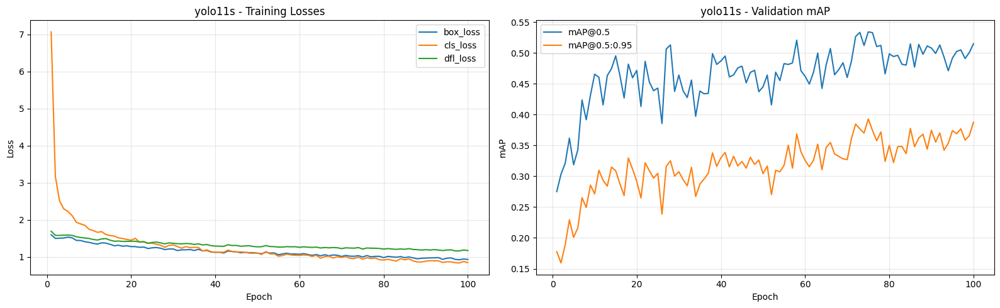

In [23]:
def plot_training_curves(results_dir, model_name):
    """Plot training loss and mAP curves from YOLO training CSV."""
    csv_path = Path(results_dir) / "results.csv"
    if not csv_path.exists():
        # Try to find it in runs directory
        possible = list(Path("runs/detect").glob(f"*{model_name}*/results.csv"))
        if possible:
            csv_path = possible[-1]
    
    if not csv_path.exists():
        display(f"No results.csv found for {model_name}")
        return
    
    df = pd.read_csv(csv_path)
    df.columns = df.columns.str.strip()
    
    fig, axes = plt.subplots(1, 2, figsize=(16, 5))
    
    # Loss curves
    ax = axes[0]
    for col in ["train/box_loss", "train/cls_loss", "train/dfl_loss"]:
        if col in df.columns:
            ax.plot(df["epoch"], df[col], label=col.split("/")[1])
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Loss")
    ax.set_title(f"{model_name} - Training Losses")
    ax.legend()
    ax.grid(True, alpha=0.3)
    
    # mAP curves
    ax = axes[1]
    for col in ["metrics/mAP50(B)", "metrics/mAP50-95(B)"]:
        if col in df.columns:
            label = "mAP@0.5" if "50(B)" in col else "mAP@0.5:0.95"
            ax.plot(df["epoch"], df[col], label=label)
    ax.set_xlabel("Epoch")
    ax.set_ylabel("mAP")
    ax.set_title(f"{model_name} - Validation mAP")
    ax.legend()
    ax.grid(True, alpha=0.3)
    
    plt.tight_layout()
    plt.show()

plot_training_curves(save_dirs["yolo11s"], "yolo11s")

### 6.2 Train YOLO11m

In [24]:
name, weights, batch = MODEL_CONFIGS[1]
model_m = YOLO(weights)
results_m = model_m.train(
    **COMMON_ARGS,
    batch=batch,
    name=f"approach1_{name}",
)
save_dirs[name] = str(model_m.trainer.save_dir)
trained_models[name] = model_m

# Evaluate on test set
best_path = Path(save_dirs[name]) / "weights" / "best.pt"
best_model = YOLO(str(best_path))
test_results[name] = evaluate_model(best_model, yaml_abs)
trained_models[name] = best_model
del model_m, results_m
gc.collect()
torch.cuda.empty_cache()


Ultralytics 8.4.34 🚀 Python-3.12.13 torch-2.10.0+cu130 CUDA:0 (NVIDIA GeForce RTX 5090, 32112MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=24, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=True, cutmix=0.0, data=/dataset/data.yaml, degrees=10, deterministic=True, device=None, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=200, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=10, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=960, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.15, mode=train, model=yolo11m.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=approach1_yolo11m, nbs=64, nms=False, opset=None, optimize=False, optimizer=auto, overlap_mask=True, patience=25,

#### YOLO11m training curves

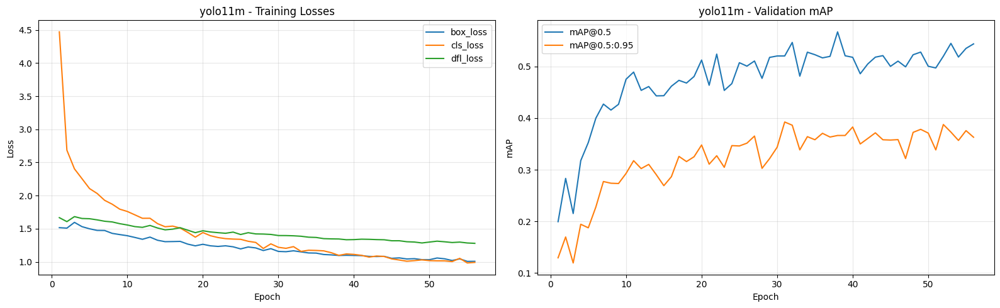

In [25]:
plot_training_curves(save_dirs["yolo11m"], "yolo11m")

### 6.3 Train YOLO11l

In [26]:
name, weights, batch = MODEL_CONFIGS[2]
model_l = YOLO(weights)
results_l = model_l.train(
    **COMMON_ARGS,
    batch=batch,
    name=f"approach1_{name}",
)
save_dirs[name] = str(model_l.trainer.save_dir)
trained_models[name] = model_l

# Evaluate on test set
best_path = Path(save_dirs[name]) / "weights" / "best.pt"
best_model = YOLO(str(best_path))
test_results[name] = evaluate_model(best_model, yaml_abs)
trained_models[name] = best_model
del model_l, results_l
gc.collect()
torch.cuda.empty_cache()


Ultralytics 8.4.34 🚀 Python-3.12.13 torch-2.10.0+cu130 CUDA:0 (NVIDIA GeForce RTX 5090, 32112MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=True, cutmix=0.0, data=/dataset/data.yaml, degrees=10, deterministic=True, device=None, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=200, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=10, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=960, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.15, mode=train, model=yolo11l.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=approach1_yolo11l, nbs=64, nms=False, opset=None, optimize=False, optimizer=auto, overlap_mask=True, patience=25,

#### YOLO11l training curves

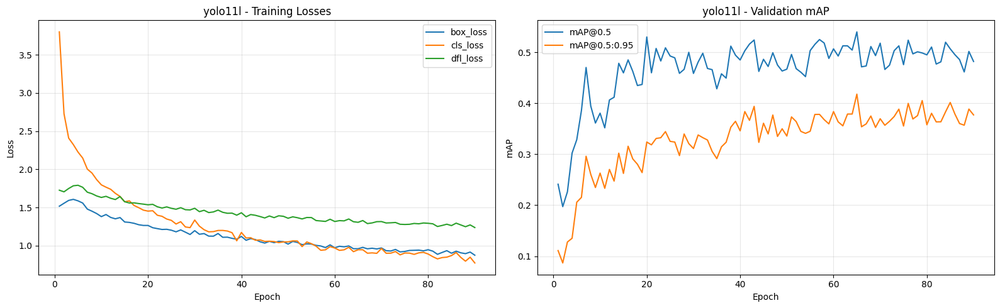

In [27]:
plot_training_curves(save_dirs["yolo11l"], "yolo11l")

### 6.4 Train YOLO26s

In [28]:
name, weights, batch = MODEL_CONFIGS[3]
model_26s = YOLO(weights)
results_26s = model_26s.train(
    **COMMON_ARGS,
    batch=batch,
    name=f"approach1_{name}",
)
save_dirs[name] = str(model_26s.trainer.save_dir)
trained_models[name] = model_26s

# Evaluate on test set
best_path = Path(save_dirs[name]) / "weights" / "best.pt"
best_model = YOLO(str(best_path))
test_results[name] = evaluate_model(best_model, yaml_abs)
trained_models[name] = best_model
del model_26s, results_26s
gc.collect()
torch.cuda.empty_cache()

Ultralytics 8.4.34 🚀 Python-3.12.13 torch-2.10.0+cu130 CUDA:0 (NVIDIA GeForce RTX 5090, 32112MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=32, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=True, cutmix=0.0, data=/dataset/data.yaml, degrees=10, deterministic=True, device=None, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=200, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=10, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=960, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.15, mode=train, model=yolo26s.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=approach1_yolo26s, nbs=64, nms=False, opset=None, optimize=False, optimizer=auto, overlap_mask=True, patience=25,

#### YOLO26s training curves

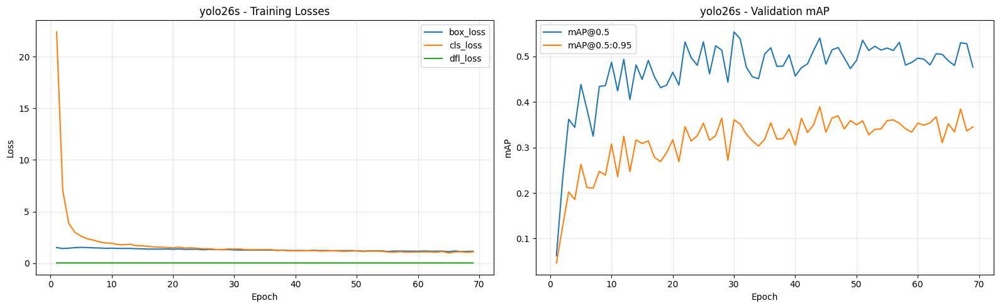

In [29]:
plot_training_curves(save_dirs["yolo26s"], "yolo26s")

### 6.5 Train YOLO26m

In [30]:
name, weights, batch = MODEL_CONFIGS[4]
model_26m = YOLO(weights)
results_26m = model_26m.train(
    **COMMON_ARGS,
    batch=batch,
    name=f"approach1_{name}",
)
save_dirs[name] = str(model_26m.trainer.save_dir)
trained_models[name] = model_26m

# Evaluate on test set
best_path = Path(save_dirs[name]) / "weights" / "best.pt"
best_model = YOLO(str(best_path))
test_results[name] = evaluate_model(best_model, yaml_abs)
trained_models[name] = best_model
del model_26m, results_26m
gc.collect()
torch.cuda.empty_cache()

Ultralytics 8.4.34 🚀 Python-3.12.13 torch-2.10.0+cu130 CUDA:0 (NVIDIA GeForce RTX 5090, 32112MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=24, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=True, cutmix=0.0, data=/dataset/data.yaml, degrees=10, deterministic=True, device=None, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=200, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=10, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=960, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.15, mode=train, model=yolo26m.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=approach1_yolo26m, nbs=64, nms=False, opset=None, optimize=False, optimizer=auto, overlap_mask=True, patience=25,

#### YOLO26m training curves

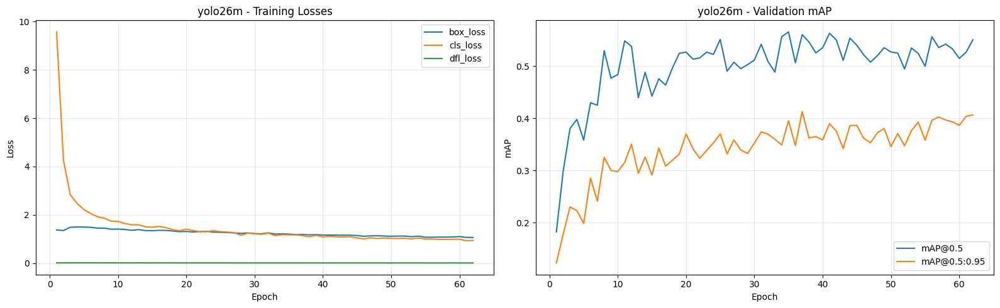

In [31]:
plot_training_curves(save_dirs["yolo26m"], "yolo26m")

### 6.6 Train YOLO26l

In [32]:
name, weights, batch = MODEL_CONFIGS[5]
model_26l = YOLO(weights)
results_26l = model_26l.train(
    **COMMON_ARGS,
    batch=batch,
    name=f"approach1_{name}",
)
save_dirs[name] = str(model_26l.trainer.save_dir)
trained_models[name] = model_26l

# Evaluate on test set
best_path = Path(save_dirs[name]) / "weights" / "best.pt"
best_model = YOLO(str(best_path))
test_results[name] = evaluate_model(best_model, yaml_abs)
trained_models[name] = best_model
del model_26l, results_26l
gc.collect()
torch.cuda.empty_cache()

Ultralytics 8.4.34 🚀 Python-3.12.13 torch-2.10.0+cu130 CUDA:0 (NVIDIA GeForce RTX 5090, 32112MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=True, cutmix=0.0, data=/dataset/data.yaml, degrees=10, deterministic=True, device=None, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=200, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=10, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=960, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.15, mode=train, model=yolo26l.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=approach1_yolo26l, nbs=64, nms=False, opset=None, optimize=False, optimizer=auto, overlap_mask=True, patience=25,

#### YOLO26l training curves

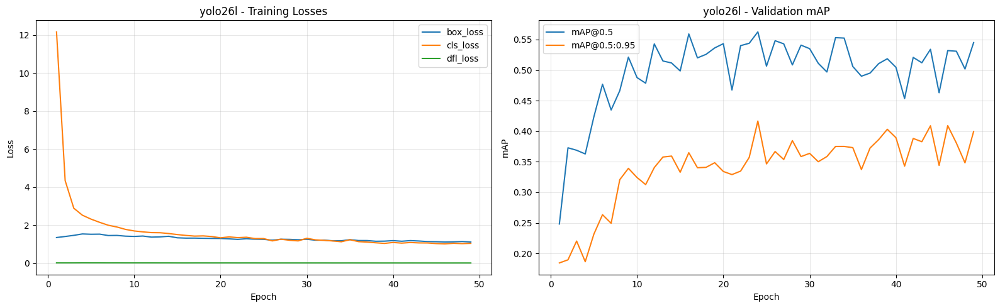

In [33]:
plot_training_curves(save_dirs["yolo26l"], "yolo26l")

## 7. Evaluate on Test Set

In [34]:
# Test evaluation already done after each training run
for name in test_results:
    r = test_results[name]
    display(f"{name}: mAP@0.5={r.box.map50:.4f}, mAP@0.5:0.95={r.box.map:.4f}")


'yolo11s: mAP@0.5=0.4810, mAP@0.5:0.95=0.3133'

'yolo11m: mAP@0.5=0.4214, mAP@0.5:0.95=0.2819'

'yolo11l: mAP@0.5=0.5006, mAP@0.5:0.95=0.3428'

'yolo26s: mAP@0.5=0.5018, mAP@0.5:0.95=0.3306'

'yolo26m: mAP@0.5=0.5246, mAP@0.5:0.95=0.3346'

'yolo26l: mAP@0.5=0.5097, mAP@0.5:0.95=0.3456'

### 7.1 Per-model evaluation: mAP, confusion matrix, per-class AP

In [35]:
def plot_evaluation(results, model_name):
    """Plot confusion matrix, per-class AP bar chart, and summary."""
    # Extract metrics
    map50 = results.box.map50
    map5095 = results.box.map
    per_class_ap50 = results.box.ap50  # array of per-class AP@0.5
    
    display(f"{model_name} | mAP@0.5: {map50:.4f} | mAP@0.5:0.95: {map5095:.4f}")
    
    fig, axes = plt.subplots(1, 2, figsize=(18, 6))
    
    # Confusion matrix
    ax = axes[0]
    cm = results.confusion_matrix.matrix  # (nc+1) x (nc+1) including background
    # Normalize rows
    cm_display = cm[:NUM_CLASSES, :NUM_CLASSES]  # exclude background for clarity
    sns.heatmap(cm_display, annot=True, fmt=".0f", cmap="Blues",
                xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, ax=ax)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("True")
    ax.set_title(f"{model_name} - Confusion Matrix (Test)")
    plt.setp(ax.get_xticklabels(), rotation=45, ha="right")
    plt.setp(ax.get_yticklabels(), rotation=0)
    
    # Per-class AP@0.5 bar chart
    ax = axes[1]
    sorted_idx = np.argsort(per_class_ap50)
    bars = ax.barh(
        [CLASS_NAMES[i] for i in sorted_idx],
        per_class_ap50[sorted_idx],
        color=[COLORS[i] for i in sorted_idx]
    )
    ax.bar_label(bars, fmt="%.3f", padding=3)
    ax.set_xlim(0, 1.15)
    ax.set_xlabel("AP@0.5")
    ax.set_title(f"{model_name} - Per-Class AP@0.5 (Test)")
    ax.axvline(x=map50, color="red", linestyle="--", alpha=0.7, label=f"mAP@0.5={map50:.3f}")
    ax.legend()
    
    plt.tight_layout()
    plt.show()

'yolo11s | mAP@0.5: 0.4810 | mAP@0.5:0.95: 0.3133'

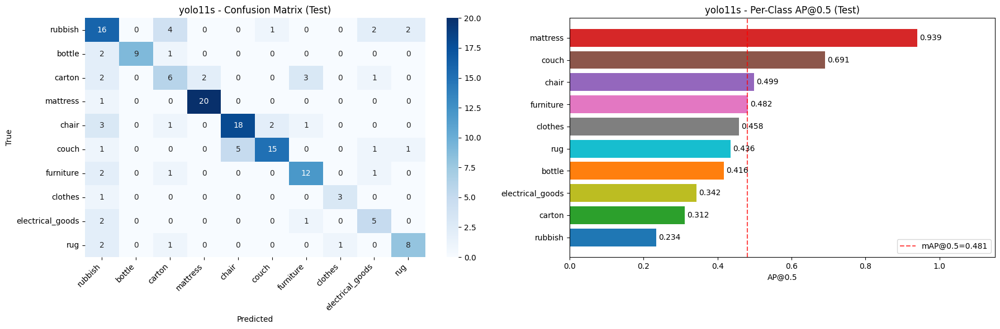

'yolo11m | mAP@0.5: 0.4214 | mAP@0.5:0.95: 0.2819'

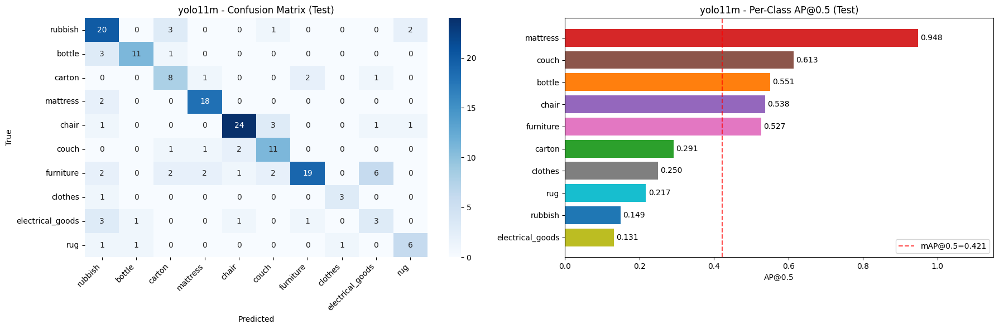

'yolo11l | mAP@0.5: 0.5006 | mAP@0.5:0.95: 0.3428'

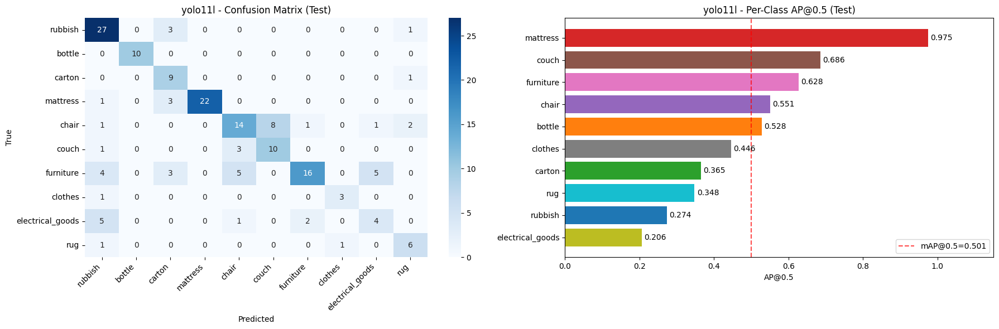

'yolo26s | mAP@0.5: 0.5018 | mAP@0.5:0.95: 0.3306'

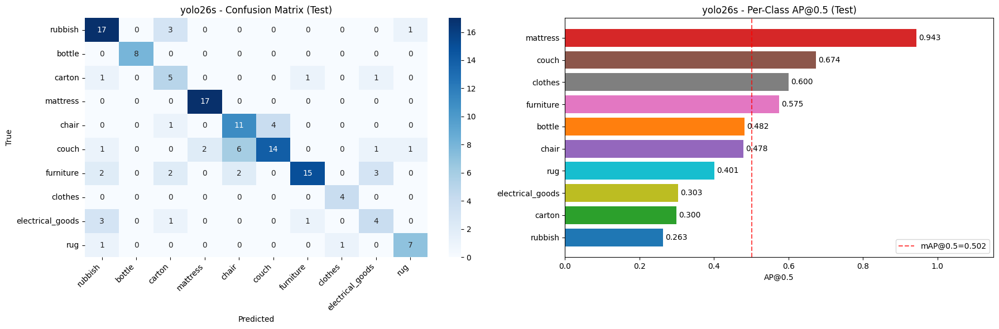

'yolo26m | mAP@0.5: 0.5246 | mAP@0.5:0.95: 0.3346'

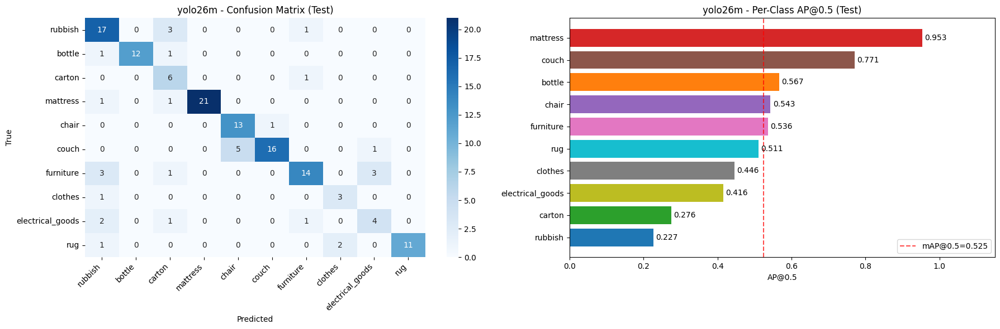

'yolo26l | mAP@0.5: 0.5097 | mAP@0.5:0.95: 0.3456'

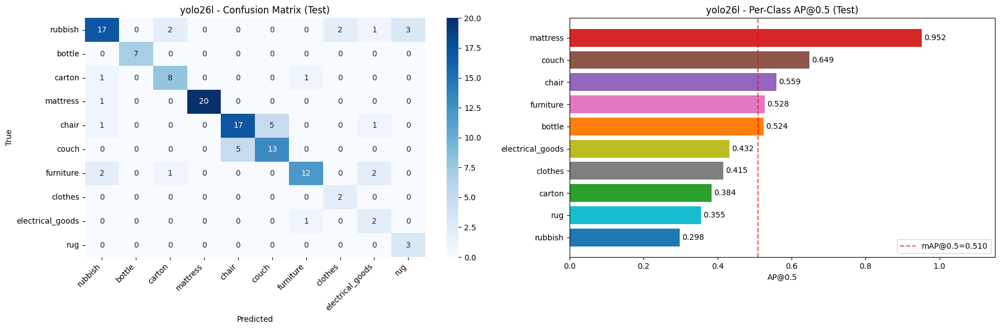

In [36]:
for name, results in test_results.items():
    plot_evaluation(results, name)

### 7.2 Sample test predictions

In [37]:
def show_predictions(model, model_name, test_images_dir, n=6):
    """Show a grid of sample predictions from the test set."""
    test_imgs = sorted(test_images_dir.glob("*"))
    test_imgs = [p for p in test_imgs if p.suffix.lower() in (".jpg", ".jpeg", ".png")]
    samples = random.sample(test_imgs, min(n, len(test_imgs)))
    
    results = model.predict(samples, imgsz=960, conf=0.25, verbose=False)
    
    cols = 3
    rows = (n + cols - 1) // cols
    fig, axes = plt.subplots(rows, cols, figsize=(18, 6 * rows))
    axes = axes.flat if hasattr(axes, "flat") else [axes]
    
    for ax, result in zip(axes, results):
        # Plot the result image with predictions drawn by ultralytics
        plotted = result.plot(line_width=2, font_size=10)
        ax.imshow(plotted[..., ::-1])  # BGR to RGB
        ax.axis("off")
        n_det = len(result.boxes)
        ax.set_title(f"{result.path.split('/')[-1][:30]} ({n_det} detections)", fontsize=9)
    
    # Hide unused axes
    for ax in list(axes)[len(results):]:
        ax.set_visible(False)
    
    fig.suptitle(f"{model_name} - Sample Test Predictions", fontsize=14)
    plt.tight_layout()
    plt.show()

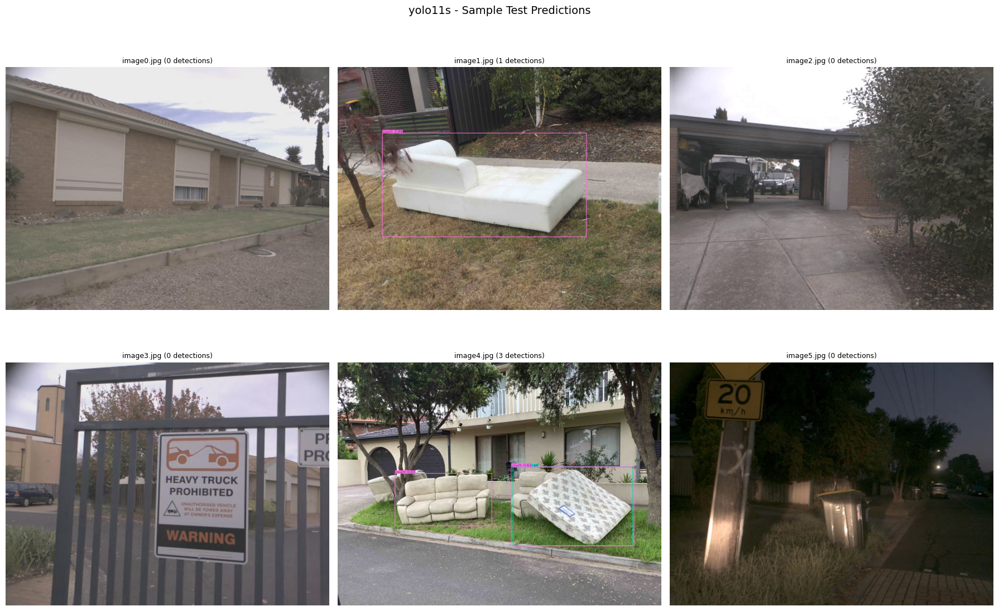

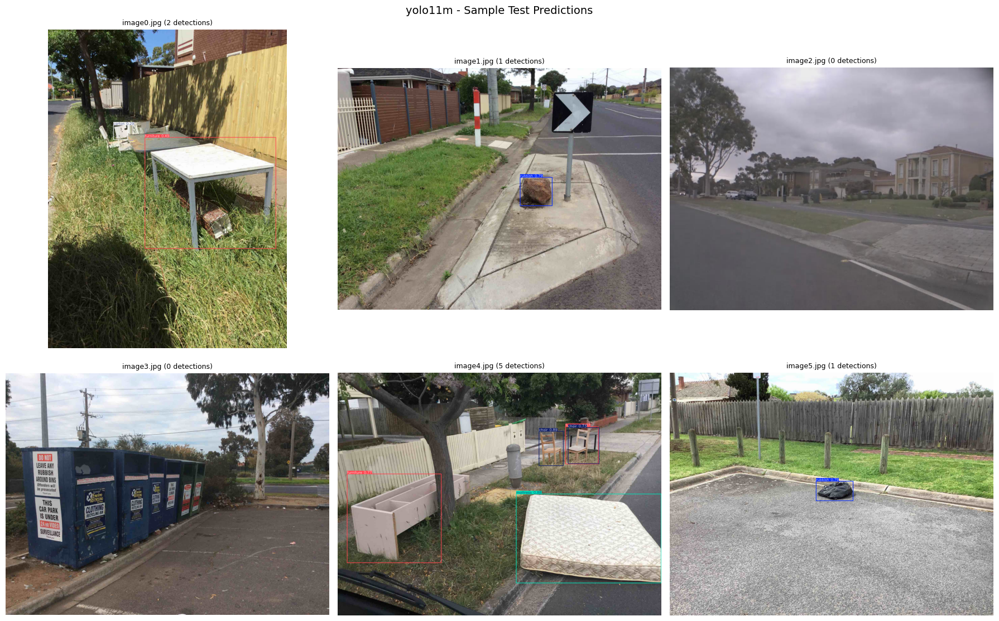

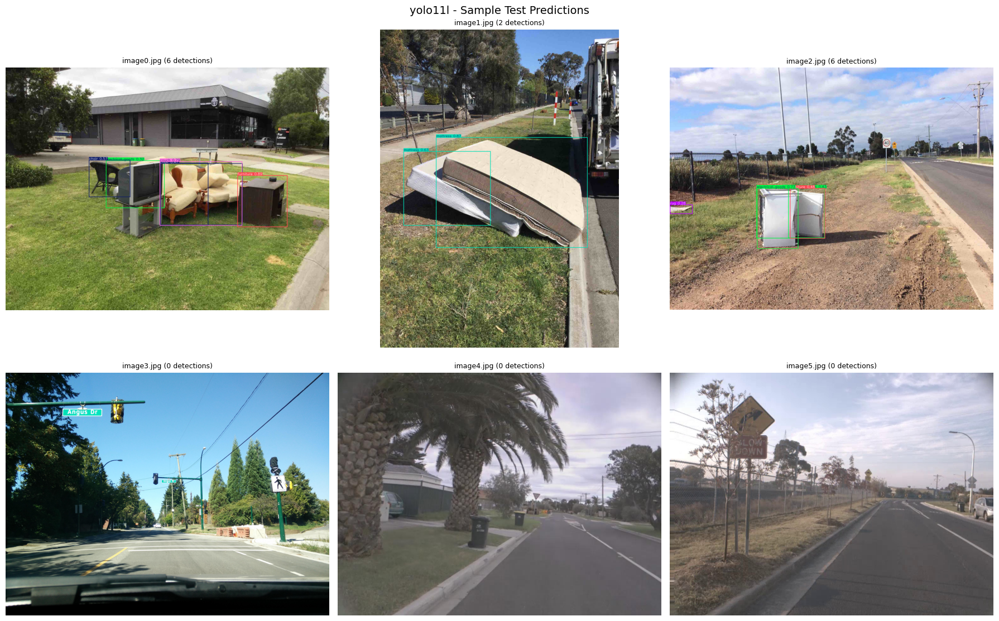

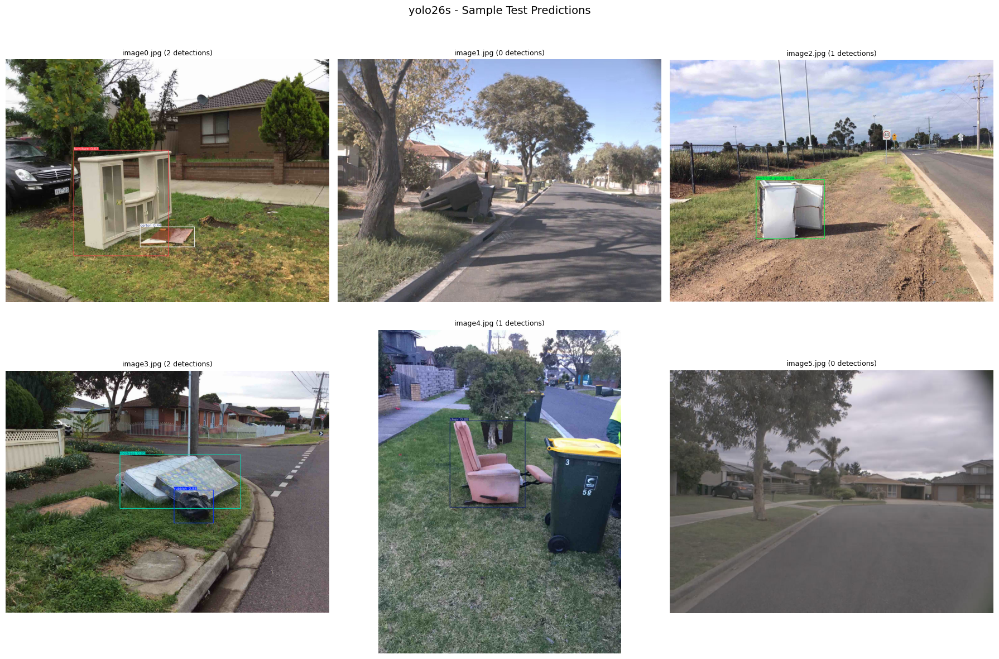

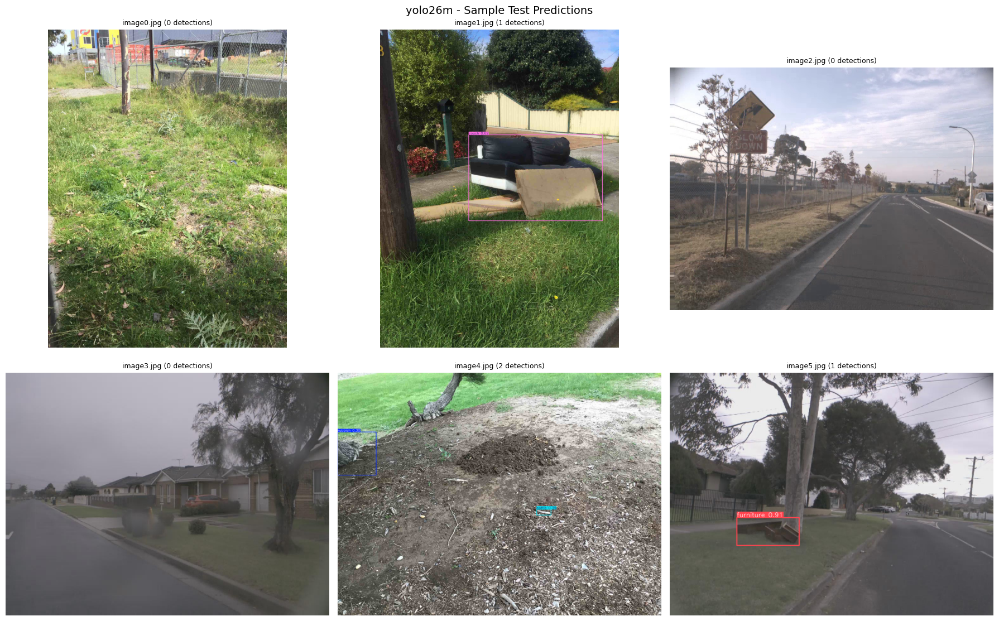

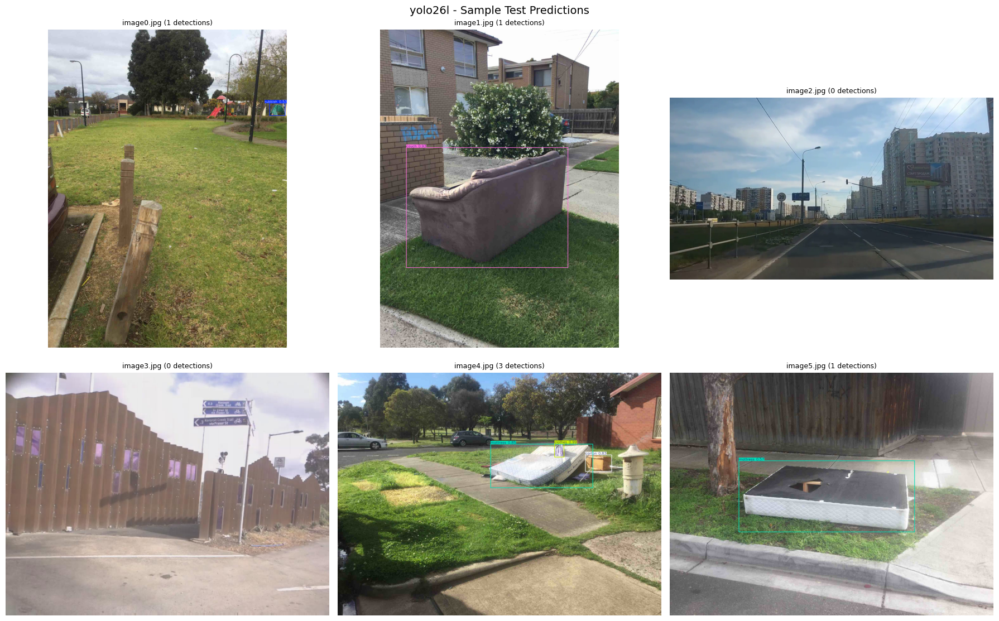

In [38]:
test_images_dir = dataset_dir / "test" / "images"
for name in save_dirs:
    best_path = Path(save_dirs[name]) / "weights" / "best.pt"
    model = YOLO(str(best_path))
    show_predictions(model, name, test_images_dir, n=6)
    del model
    gc.collect()
    torch.cuda.empty_cache()

### 7.3 Save all test predictions to disk

In [39]:
# Save ALL test images with predicted bounding boxes drawn on them
test_imgs_all = sorted(test_images_dir.glob("*"))
test_imgs_all = [p for p in test_imgs_all if p.suffix.lower() in (".jpg", ".jpeg", ".png")]

for name in save_dirs:
    best_path = Path(save_dirs[name]) / "weights" / "best.pt"
    model = YOLO(str(best_path))
    save_dir = Path(f"multiclass_{name}_predictions")
    save_dir.mkdir(exist_ok=True)

    for img_path in tqdm(test_imgs_all, desc=f"Saving {name} predictions"):
        result = model.predict(str(img_path), imgsz=960, conf=0.25, verbose=False)[0]
        plotted = result.plot(line_width=2, font_size=10)
        out_path = save_dir / img_path.name
        Image.fromarray(plotted[..., ::-1]).save(out_path)

    display(f"{name}: saved {len(test_imgs_all)} predictions to {save_dir}")
    del model
    gc.collect()
    torch.cuda.empty_cache()

Saving yolo11s predictions:   0%|          | 0/240 [00:00<?, ?it/s]

'yolo11s: saved 240 predictions to multiclass_yolo11s_predictions'

Saving yolo11m predictions:   0%|          | 0/240 [00:00<?, ?it/s]

'yolo11m: saved 240 predictions to multiclass_yolo11m_predictions'

Saving yolo11l predictions:   0%|          | 0/240 [00:00<?, ?it/s]

'yolo11l: saved 240 predictions to multiclass_yolo11l_predictions'

... (2 outputs left out)

Saving yolo26m predictions:   0%|          | 0/240 [00:00<?, ?it/s]

'yolo26m: saved 240 predictions to multiclass_yolo26m_predictions'

Saving yolo26l predictions:   0%|          | 0/240 [00:00<?, ?it/s]

'yolo26l: saved 240 predictions to multiclass_yolo26l_predictions'

## 8. Compare Models

In [40]:
# Build comparison table
comparison_rows = []

for name in ["yolo11s", "yolo11m", "yolo11l", "yolo26s", "yolo26m", "yolo26l"]:
    results = test_results[name]
    best_path = Path(save_dirs[name]) / "weights" / "best.pt"
    model = YOLO(str(best_path))

    map50 = results.box.map50
    map5095 = results.box.map
    per_class_ap50 = results.box.ap50

    # Macro AP (mean of all per-class AP@0.5)
    macro_ap = np.mean(per_class_ap50)

    # Minority class macro AP
    minority_ap = np.mean([per_class_ap50[i] for i in MINORITY_CLASSES])

    # Parameter count
    n_params = sum(p.numel() for p in model.model.parameters()) / 1e6

    # Inference speed (from validation results)
    speed = results.speed
    inf_ms = speed.get("inference", 0)

    comparison_rows.append({
        "Model": name,
        "Params (M)": f"{n_params:.1f}",
        "mAP@0.5": f"{map50:.4f}",
        "mAP@0.5:0.95": f"{map5095:.4f}",
        "Macro AP@0.5": f"{macro_ap:.4f}",
        "Minority AP@0.5": f"{minority_ap:.4f}",
        "Inference (ms)": f"{inf_ms:.1f}",
    })
    del model
    gc.collect()
    torch.cuda.empty_cache()

comparison_df = pd.DataFrame(comparison_rows)
comparison_df

,Model,Params (M),mAP@0.5,mAP@0.5:0.95,Macro AP@0.5,Minority AP@0.5,Inference (ms)
0,yolo11s,9.4,0.4810,0.3133,0.4810,0.4132,1.5
1,yolo11m,20.1,0.4214,0.2819,0.4214,0.2872,3.4
2,yolo11l,25.3,0.5006,0.3428,0.5006,0.3818,4.3
3,yolo26s,10.0,0.5018,0.3306,0.5018,0.4467,1.5
4,yolo26m,21.8,0.5246,0.3346,0.5246,0.4849,3.4
5,yolo26l,26.2,0.5097,0.3456,0.5097,0.4317,4.3


### 8.1 mAP comparison bar chart

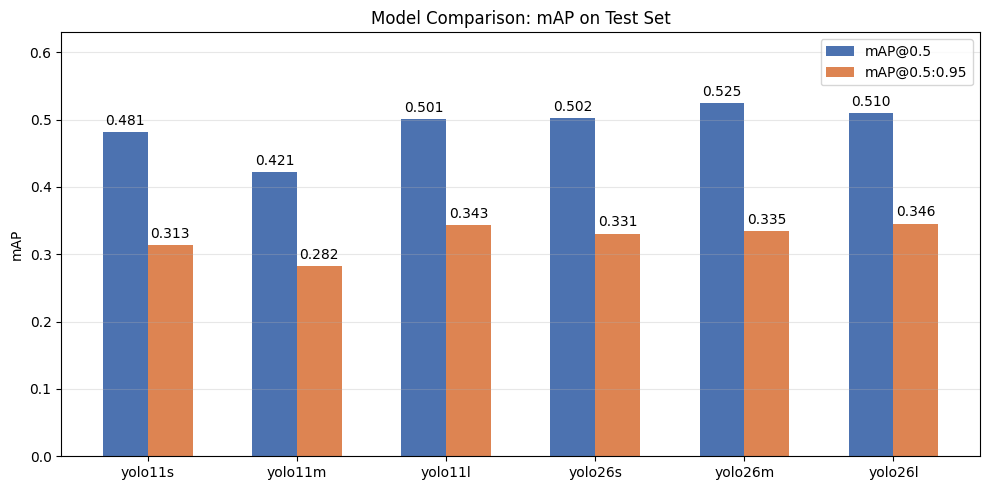

In [41]:
fig, ax = plt.subplots(figsize=(10, 5))
model_names = ["yolo11s", "yolo11m", "yolo11l", "yolo26s", "yolo26m", "yolo26l"]
x = np.arange(len(model_names))
width = 0.3

map50_vals = [test_results[n].box.map50 for n in model_names]
map5095_vals = [test_results[n].box.map for n in model_names]

bars1 = ax.bar(x - width/2, map50_vals, width, label="mAP@0.5", color="#4C72B0")
bars2 = ax.bar(x + width/2, map5095_vals, width, label="mAP@0.5:0.95", color="#DD8452")
ax.bar_label(bars1, fmt="%.3f", padding=3)
ax.bar_label(bars2, fmt="%.3f", padding=3)

ax.set_xticks(x)
ax.set_xticklabels(model_names)
ax.set_ylabel("mAP")
ax.set_title("Model Comparison: mAP on Test Set")
ax.legend()
ax.set_ylim(0, max(map50_vals) * 1.2)
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

### 8.2 Per-class AP comparison across models

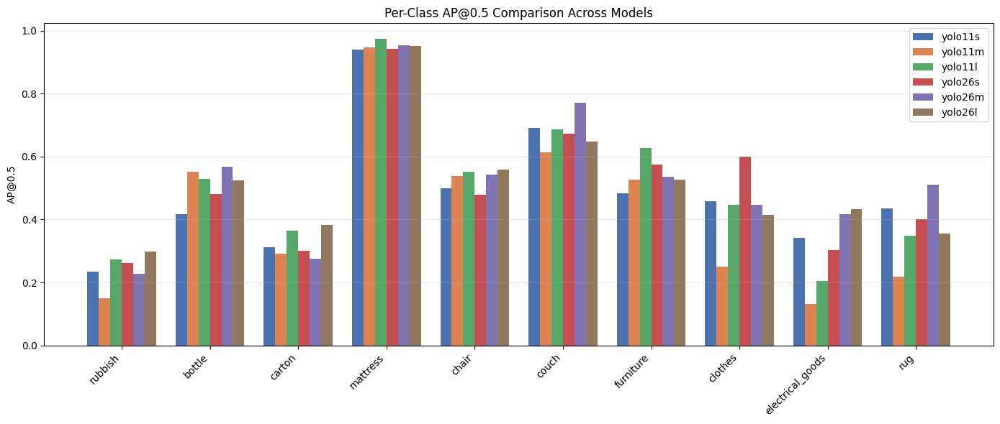

In [42]:
fig, ax = plt.subplots(figsize=(14, 6))
x = np.arange(NUM_CLASSES)
width = 0.13
colors_models = ["#4C72B0", "#DD8452", "#55A868", "#C44E52", "#8172B2", "#937860"]

for i, name in enumerate(model_names):
    ap50 = test_results[name].box.ap50
    ax.bar(x + i * width, ap50, width, label=name, color=colors_models[i])

ax.set_xticks(x + width * 2.5)
ax.set_xticklabels(CLASS_NAMES, rotation=45, ha="right")
ax.set_ylabel("AP@0.5")
ax.set_title("Per-Class AP@0.5 Comparison Across Models")
ax.legend()
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

### 8.3 Identify best model

In [43]:
# Identify the best model by mAP@0.5:0.95
best_name = max(model_names, key=lambda n: test_results[n].box.map)
best_map50 = test_results[best_name].box.map50
best_map5095 = test_results[best_name].box.map

best_path = Path(save_dirs[best_name]) / "weights" / "best.pt"

display(f"Best model: {best_name}")
display(f"  mAP@0.5:     {best_map50:.4f}")
display(f"  mAP@0.5:0.95: {best_map5095:.4f}")
display(f"  Weights: {best_path}")

'Best model: yolo26l'

'  mAP@0.5:     0.5097'

'  mAP@0.5:0.95: 0.3456'

'  Weights: /runs/detect/approach1_yolo26l/weights/best.pt'